# Bài toán 1 — Từ role + kinh nghiệm đến kỹ năng

Tìm các luật kết hợp có dạng `{role, exp_level} → skill`. Trong dữ liệu, cặp role–kinh nghiệm được gộp thành item `ROLE_<role_exp>`. So sánh luật Apriori/FP-Growth với baseline đếm tần suất skill trong đúng nhóm role–kinh nghiệm.

## 1. Nạp dữ liệu và kiểm tra nhãn role_exp

`role_exp` được tạo ở notebook EDA từ `role_group` và `exp_level`. Ma trận giao dịch phải có đúng một cột `ROLE_<role_exp>` bật trên mỗi dòng, đúng thứ tự với `processed_jobs.csv`.

### Bước 1: Chuẩn bị thư viện và tham số

Đặt ngưỡng và đường dẫn trước để các bước sau dùng cùng một cấu hình.

In [44]:
import ast, time, tracemalloc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from sklearn.model_selection import StratifiedKFold

DATA_DIR = Path("../data/processed")
RESULT_DIR = Path("../result/problem_1")
FIGURES_DIR = RESULT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE, N_SPLITS = 42, 5
MIN_ROLE_EXP_JOBS = 8
MIN_SUPPORT_COUNT, MIN_CONFIDENCE, MIN_LIFT = 5, 0.20, 1.20
TOP_K_VALUES = [5, 10]


### Bước 2: Đọc lại danh sách kỹ năng

Cột đã là list từ notebook tiền xử lý; hàm này chỉ bảo vệ trường hợp CSV đọc list thành chuỗi.

In [45]:
def parse_skill_list(value):
    if isinstance(value, list): parsed = value
    elif isinstance(value, str):
        try: parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError): parsed = []
    else: parsed = []
    if not isinstance(parsed, list): return []
    return list(dict.fromkeys(x.strip() for x in parsed if isinstance(x, str) and x.strip()))


### Bước 3: Nạp tin và danh sách skill

In [46]:
jobs_source = pd.read_csv(DATA_DIR / "processed_jobs.csv")
jobs_source["skills_final"] = jobs_source["skills_final"].apply(parse_skill_list)
all_known_jobs = jobs_source[jobs_source.role_exp.ne("Other")].reset_index(drop=True)


### Bước 4: Nạp ma trận giao dịch

In [47]:
transactions_source = pd.read_csv(DATA_DIR / "transaction_matrix.csv").fillna(False).astype(bool).reset_index(drop=True)
if len(all_known_jobs) != len(transactions_source):
    raise ValueError("Số dòng processed_jobs sau khi bỏ Other không khớp ma trận giao dịch")


### Bước 5: Kiểm tra hai nguồn có cùng thứ tự và nhãn

In [48]:
role_item_cols = [c for c in transactions_source if c.startswith("ROLE_")]
skill_cols = [c for c in transactions_source if not c.startswith("ROLE_")]
encoded_role_exp = transactions_source[role_item_cols].idxmax(axis=1).str.replace("ROLE_", "", n=1, regex=False)
assert transactions_source[role_item_cols].sum(axis=1).eq(1).all()
assert encoded_role_exp.equals(all_known_jobs.role_exp)
print("Đã kiểm tra thứ tự dòng và nhãn ROLE_<role_exp>.")
print("Tin thuộc role khác Other:", len(all_known_jobs), "| role_exp:", all_known_jobs.role_exp.nunique())


Đã kiểm tra thứ tự dòng và nhãn ROLE_<role_exp>.
Tin thuộc role khác Other: 1830 | role_exp: 39


## 2. Role_exp có nhóm quá ít tin

Trước khi chia 5-fold, cần kiểm tra số tin trong từng cặp role–kinh nghiệm. Nhóm quá nhỏ có thể vắng khỏi một fold train, khiến luật/baseline không có dữ liệu để học.

In [49]:
has_skills = all_known_jobs.skills_final.map(bool)
skill_jobs = all_known_jobs.loc[has_skills].reset_index(drop=True)
skill_matrix = transactions_source.loc[has_skills].reset_index(drop=True)
role_exp_counts = skill_jobs.role_exp.value_counts().sort_values()
sparse_role_exp = role_exp_counts[role_exp_counts < MIN_ROLE_EXP_JOBS]
print("Tổ hợp role_exp có dưới", MIN_ROLE_EXP_JOBS, "tin:", len(sparse_role_exp))
print("Tin thuộc các tổ hợp thưa:", int(sparse_role_exp.sum()))
display(sparse_role_exp.rename("Số tin").to_frame())

Tổ hợp role_exp có dưới 8 tin: 5
Tin thuộc các tổ hợp thưa: 17


,Số tin
role_exp,
Mobile Dev | Intern,1
Game Dev | Intern,3
Frontend Dev | Intern,3
Sales / Marketing / Support | Senior,4
Game Dev | Junior,6


### Cách xử lý

Không gộp Junior, Senior, Fresher hay Intern vào nhau vì sẽ đổi ý nghĩa của feature. Giữ lại để EDA mô tả, nhưng loại các nhóm dưới 8 tin khỏi phần huấn luyện/đánh giá của notebook này. Các dòng bị loại được đếm và báo cáo rõ.

In [50]:
stable_role_exp = role_exp_counts[role_exp_counts >= MIN_ROLE_EXP_JOBS].index
eligible_mask = skill_jobs.role_exp.isin(stable_role_exp)
excluded_sparse_jobs = int((~eligible_mask).sum())
jobs = skill_jobs.loc[eligible_mask].reset_index(drop=True)
transactions = skill_matrix.loc[eligible_mask].reset_index(drop=True)
assert jobs.role_exp.value_counts().min() >= MIN_ROLE_EXP_JOBS
print("Tin có skill:", len(skill_jobs))
print("Loại do role_exp dưới ngưỡng:", excluded_sparse_jobs)
print("Tin dùng cho 5-fold:", len(jobs), "| số nhóm role_exp:", jobs.role_exp.nunique())
display(jobs.role_exp.value_counts().sort_index().rename("Số tin").to_frame())

Tin có skill: 1501
Loại do role_exp dưới ngưỡng: 17
Tin dùng cho 5-fold: 1484 | số nhóm role_exp: 34


,Số tin
role_exp,
BA / PM / Product | Fresher,49
BA / PM / Product | Intern,22
BA / PM / Product | Junior,148
BA / PM / Product | Senior,60
Backend / Fullstack Dev | Fresher,42
Backend / Fullstack Dev | Intern,28
Backend / Fullstack Dev | Junior,133
Backend / Fullstack Dev | Senior,39
Data / AI | Fresher,15


## 3. Đối chứng: tần suất skill trong cùng role_exp

Baseline đếm số tin train có từng skill **trong cùng một cặp role–kinh nghiệm**, rồi xếp hạng giảm dần. Baseline không lọc theo support, confidence hay lift; vì vậy nó là mốc trực tiếp để xem việc lọc luật có làm mất kỹ năng hữu ích hay không.

In [51]:
def popularity_rankings(train_jobs, train_matrix):
    rankings = {}
    segments = train_jobs.role_exp.reset_index(drop=True)
    skills = train_matrix[skill_cols].reset_index(drop=True)
    for segment in segments.unique():
        positions = np.flatnonzero(segments.eq(segment).to_numpy())
        counts = skills.iloc[positions].sum(axis=0)
        rankings[segment] = counts.sort_values(ascending=False, kind="stable").index.tolist()
    return rankings

baseline_example = popularity_rankings(jobs, transactions)
example_segment = jobs.role_exp.value_counts().index[0]
print("Ví dụ baseline —", example_segment)
print(baseline_example[example_segment][:10])

Ví dụ baseline — Designer / Creative | Fresher
['Photoshop', 'Illustrator', 'After Effects', 'InDesign', 'Figma', 'Premiere', 'AI', 'Canva', 'Capcut', '3ds Max']


## 4. Khai phá luật `{role_exp} → skill`

`min_support` được đặt theo số tin tuyệt đối: luật phải có ít nhất 5 tin hỗ trợ. `max_len=2` là đủ cho một item role_exp ở vế trái và một skill ở vế phải.

### Bước 1: Tạo hàm khai phá luật

Chỉ chấp nhận luật có một antecedent role_exp và một consequent là skill.

In [52]:
def mine_role_exp_rules(matrix, method):
    miner = apriori if method == "Apriori" else fpgrowth
    frequent = miner(matrix, min_support=MIN_SUPPORT_COUNT / len(matrix),
                     use_colnames=True, max_len=2)
    columns = ["role_exp", "skill", "support", "support_count", "confidence", "lift"]
    if frequent.empty or not frequent.itemsets.map(len).ge(2).any():
        return frequent, pd.DataFrame(columns=columns)
    rules = association_rules(frequent, metric="confidence", min_threshold=MIN_CONFIDENCE)
    if rules.empty: return frequent, pd.DataFrame(columns=columns)
    rules = rules[
        rules.antecedents.map(lambda x: len(x) == 1 and str(next(iter(x))).startswith("ROLE_"))
        & rules.consequents.map(lambda x: len(x) == 1 and not str(next(iter(x))).startswith("ROLE_"))
        & (rules.lift >= MIN_LIFT)
        & (rules.support * len(matrix) >= MIN_SUPPORT_COUNT - 1e-9)
    ].copy()
    if rules.empty: return frequent, pd.DataFrame(columns=columns)
    rules["role_exp"] = rules.antecedents.map(lambda x: str(next(iter(x))).replace("ROLE_", "", 1))
    rules["skill"] = rules.consequents.map(lambda x: str(next(iter(x))))
    rules["support_count"] = (rules.support * len(matrix)).round().astype(int)
    return frequent, rules[columns].sort_values(
        ["role_exp", "confidence", "lift", "support"],
        ascending=[True, False, False, False]).reset_index(drop=True)


### Bước 2: Xếp kỹ năng theo luật tìm được

In [53]:
def rule_rankings(rules, all_segments):
    result = {segment: [] for segment in all_segments}
    for segment, group in rules.groupby("role_exp"):
        result[segment] = group.sort_values(
            ["confidence", "lift", "support"], ascending=False).skill.drop_duplicates().tolist()
    return result


### Bước 3: Chạy thử và đọc một vài luật

In [54]:
example_itemsets, example_rules = mine_role_exp_rules(transactions, "Apriori")
print("Luật Apriori trên toàn bộ dữ liệu:", len(example_rules))
display(example_rules.head(10))


Luật Apriori trên toàn bộ dữ liệu: 159


,role_exp,skill,support,support_count,confidence,lift
0,BA / PM / Product | Fresher,ERP,0.008086,12,0.244898,4.911197
1,BA / PM / Product | Fresher,Agile,0.006739,10,0.204082,1.802721
2,BA / PM / Product | Intern,Microsoft Office,0.007412,11,0.500000,6.081967
3,BA / PM / Product | Intern,Excel,0.004043,6,0.272727,3.929391
4,BA / PM / Product | Junior,Agile,0.026954,40,0.270270,2.387387
5,BA / PM / Product | Senior,Agile,0.013477,20,0.333333,2.944444
6,BA / PM / Product | Senior,Project Management,0.008760,13,0.216667,6.183333
7,BA / PM / Product | Senior,Cloud,0.008086,12,0.200000,1.991946
8,Backend / Fullstack Dev | Fresher,JavaScript,0.010782,16,0.380952,3.925926
9,Backend / Fullstack Dev | Fresher,MySQL,0.010108,15,0.357143,4.416667


## 5. Chấm chất lượng gợi ý

`K` là số gợi ý đầu danh sách được chấm, không phải số fold. `Precision@K` là tỷ lệ gợi ý đúng trong K vị trí; `Recall@K` là phần skill của tin test được tìm lại; `Hit@K` cho biết tin có ít nhất một gợi ý đúng; `NDCG@K` tính thêm vị trí của gợi ý đúng. Nếu luật trả ít hơn K kỹ năng, coverage cho biết tỷ lệ vị trí được lấp; precision vẫn chia cho K.

In [55]:
import math

def metrics_at_k(prediction, relevant, k):
    relevant = set(relevant) & set(skill_cols)
    prediction = list(dict.fromkeys(prediction))[:k]
    hits = [int(x in relevant) for x in prediction]
    dcg = sum(hit / math.log2(i + 2) for i, hit in enumerate(hits))
    idcg = sum(1 / math.log2(i + 2) for i in range(min(k, len(relevant))))
    return {"Precision@K": sum(hits) / k,
        "Recall@K": sum(hits) / len(relevant) if relevant else 0.0,
        "Hit@K": float(any(hits)), "NDCG@K": dcg / idcg if idcg else 0.0,
        "Recommendation coverage": len(prediction) / k}

## 6. So sánh bằng stratified 5-fold

Chia theo `role_exp` để mỗi tổ hợp đủ mẫu xuất hiện trong cả train và test. Mỗi lần, Apriori, FP-Growth và baseline đều chỉ học từ bốn fold; điểm được tính trên tin ở fold còn lại.

### Bước 1: Chạy từng fold và ghi lại dự đoán

In [56]:
splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
quality_rows, benchmark_rows, itemsets_match = [], [], []
metric_names = ["Precision@K", "Recall@K", "Hit@K", "NDCG@K", "Recommendation coverage"]
for fold, (tr, te) in enumerate(splitter.split(np.zeros(len(jobs)), jobs.role_exp), 1):
    train_jobs, test_jobs = jobs.iloc[tr].reset_index(drop=True), jobs.iloc[te].reset_index(drop=True)
    train_matrix = transactions.iloc[tr].reset_index(drop=True)
    rankings = {}; current_itemsets = {}
    for method in ["Apriori", "FP-Growth"]:
        tracemalloc.start(); started = time.perf_counter()
        itemsets, rules = mine_role_exp_rules(train_matrix, method)
        elapsed = time.perf_counter() - started
        _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
        rankings[method] = rule_rankings(rules, jobs.role_exp.unique())
        current_itemsets[method] = {frozenset(x) for x in itemsets.get("itemsets", [])}
        benchmark_rows.append({"fold": fold, "Model": method, "Runtime (s)": elapsed,
            "Memory Usage (MB)": peak / 2**20, "Number of Rules": len(rules)})
    itemsets_match.append(current_itemsets["Apriori"] == current_itemsets["FP-Growth"])
    tracemalloc.start(); started = time.perf_counter()
    rankings["Role+Experience Popularity"] = popularity_rankings(train_jobs, train_matrix)
    elapsed = time.perf_counter() - started
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    benchmark_rows.append({"fold": fold, "Model": "Role+Experience Popularity", "Runtime (s)": elapsed,
        "Memory Usage (MB)": peak / 2**20, "Number of Rules": np.nan})
    for model, ranking in rankings.items():
        for k in TOP_K_VALUES:
            scores = [metrics_at_k(ranking.get(row.role_exp, []), row.skills_final, k)
                      for row in test_jobs.itertuples(index=False)]
            quality_rows.append({"fold": fold, "Model": model, "K": k,
                **{m: float(np.mean([x[m] for x in scores])) for m in metric_names},
                "Test jobs": len(scores)})


### Bước 2: Tổng hợp điểm và tài nguyên qua 5 fold

In [57]:
fold_quality = pd.DataFrame(quality_rows)
quality_summary = fold_quality.groupby(["Model", "K"])[metric_names].agg(["mean", "std"]).reset_index()
quality_summary.columns = ["Model", "K", *[f"{m}_{stat}" for m in metric_names for stat in ["mean", "std"]]]
bench = pd.DataFrame(benchmark_rows)
benchmark_summary = bench.groupby("Model").agg(
    **{"Runtime median (s)": ("Runtime (s)", "median"), "Number of Rules mean": ("Number of Rules", "mean"),
       "Memory Usage median (MB)": ("Memory Usage (MB)", "median")}).reset_index()
summary = quality_summary.merge(benchmark_summary, on="Model", how="left")
print("Apriori và FP-Growth có cùng itemsets ở cả 5 fold:", all(itemsets_match))
display(summary.rename(columns={"Model": "Phương pháp"}).round(4))


Apriori và FP-Growth có cùng itemsets ở cả 5 fold: True


,Phương pháp,K,Precision@K_mean,Precision@K_std,Recall@K_mean,Recall@K_std,Hit@K_mean,Hit@K_std,NDCG@K_mean,NDCG@K_std,Recommendation coverage_mean,Recommendation coverage_std,Runtime median (s),Number of Rules mean,Memory Usage median (MB)
0,Apriori,5,0.2751,0.0070,0.3281,0.0202,0.6617,0.0158,0.4069,0.0181,0.7361,0.0203,0.5756,147.8,87.1362
1,Apriori,10,0.1689,0.0082,0.3618,0.0259,0.6866,0.0179,0.3941,0.0209,0.5094,0.0192,0.5756,147.8,87.1362
2,FP-Growth,5,0.2751,0.0070,0.3281,0.0202,0.6617,0.0158,0.4069,0.0181,0.7361,0.0203,1.3053,147.8,4.2842
3,FP-Growth,10,0.1689,0.0082,0.3618,0.0259,0.6866,0.0179,0.3941,0.0209,0.5094,0.0192,1.3053,147.8,4.2842
4,Role+Experience Popularity,5,0.3139,0.0099,0.3854,0.0176,0.7439,0.0292,0.4494,0.0149,1.0000,0.0000,1.7273,NaN,0.6801
5,Role+Experience Popularity,10,0.2300,0.0100,0.5224,0.0261,0.8423,0.0319,0.4834,0.0174,1.0000,0.0000,1.7273,NaN,0.6801


## 7. Rà soát luật cuối và kết quả theo role_exp

Bảng luật cuối được khai phá từ toàn bộ tập đủ điều kiện để xem các quan hệ tìm thấy. Bảng này dùng để diễn giải; điểm chất lượng vẫn là kết quả 5-fold ở trên.

In [58]:
_, final_rules_apriori = mine_role_exp_rules(transactions, "Apriori")
_, final_rules_fp = mine_role_exp_rules(transactions, "FP-Growth")
print("Số luật cuối — Apriori:", len(final_rules_apriori), "| FP-Growth:", len(final_rules_fp))
print("Luật Apriori tiêu biểu:")
display(final_rules_apriori.sort_values(["confidence", "lift"], ascending=False).head(20))
coverage = pd.DataFrame({"role_exp": sorted(jobs.role_exp.unique())})
coverage["số tin"] = coverage.role_exp.map(jobs.role_exp.value_counts())
coverage["số luật"] = coverage.role_exp.map(final_rules_apriori.role_exp.value_counts()).fillna(0).astype(int)
display(coverage.rename(columns={"role_exp": "Role + kinh nghiệm"}))

Số luật cuối — Apriori: 159 | FP-Growth: 159
Luật Apriori tiêu biểu:


,role_exp,skill,support,support_count,confidence,lift
67,Designer / Creative | Fresher,Photoshop,0.105795,157,0.887006,3.826501
99,Frontend Dev | Fresher,Git,0.004717,7,0.875000,8.542763
114,Frontend Dev | Senior,React,0.006065,9,0.818182,11.454545
76,Designer / Creative | Junior,Photoshop,0.080189,119,0.815068,3.516168
73,Designer / Creative | Intern,Photoshop,0.035714,53,0.803030,3.464235
133,Mobile Dev | Senior,Android,0.004717,7,0.777778,26.232323
100,Frontend Dev | Fresher,JavaScript,0.004043,6,0.750000,7.729167
153,Sales / Marketing / Support | Intern,Microsoft Office,0.016173,24,0.727273,8.846498
77,Designer / Creative | Junior,Illustrator,0.069407,103,0.705479,3.820918
68,Designer / Creative | Fresher,Illustrator,0.080863,120,0.677966,3.671904


,Role + kinh nghiệm,số tin,số luật
0,BA / PM / Product | Fresher,49,2
1,BA / PM / Product | Intern,22,2
2,BA / PM / Product | Junior,148,1
3,BA / PM / Product | Senior,60,3
4,Backend / Fullstack Dev | Fresher,42,10
5,Backend / Fullstack Dev | Intern,28,5
6,Backend / Fullstack Dev | Junior,133,13
7,Backend / Fullstack Dev | Senior,39,18
8,Data / AI | Fresher,15,3
9,Data / AI | Intern,10,1


## 8. Biểu đồ và kết quả gọn

Trong `result/problem_1/` chỉ lưu hai tệp chính: `summary.csv` (chất lượng gợi ý và benchmark) và một biểu đồ tổng hợp. Bảng luật chi tiết vẫn xem được trực tiếp trong notebook.

### Bước 1: Vẽ biểu đồ so sánh chất lượng và tài nguyên

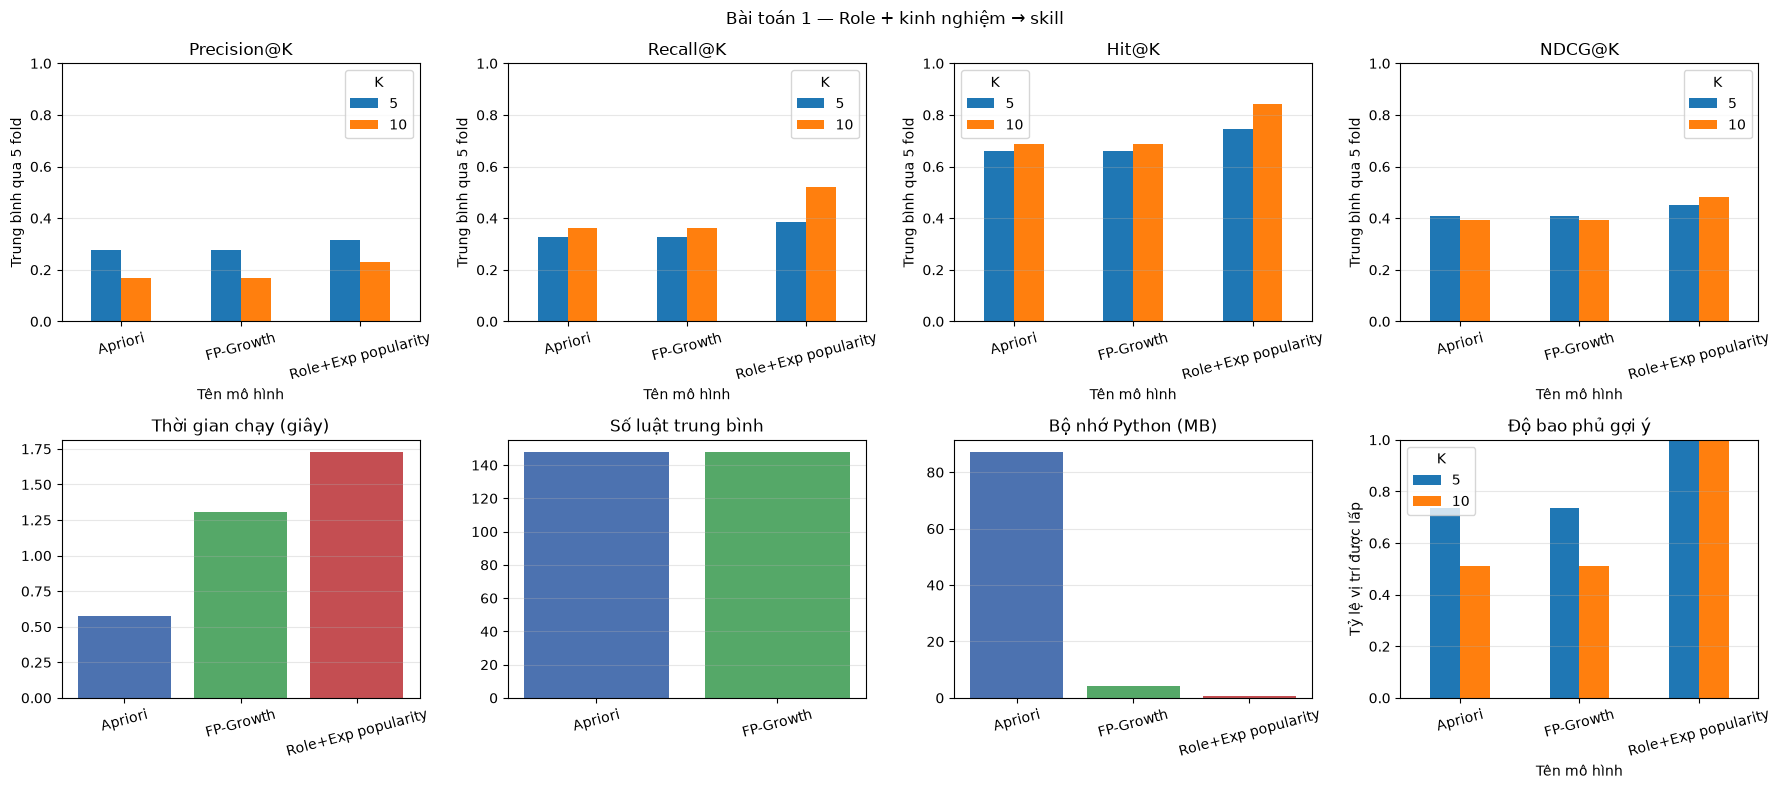

In [59]:
RESULT_DIR.mkdir(parents=True, exist_ok=True)
short = {"Apriori": "Apriori", "FP-Growth": "FP-Growth",
         "Role+Experience Popularity": "Role+Exp popularity"}
plot_data = summary.copy(); plot_data["Tên mô hình"] = plot_data.Model.map(short)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, metric, title in zip(axes[0], metric_names[:4],
    ["Precision@K", "Recall@K", "Hit@K", "NDCG@K"]):
    plot_data.pivot(index="Tên mô hình", columns="K", values=f"{metric}_mean").plot(
        kind="bar", ax=ax, ylim=(0, 1), rot=15)
    ax.set_title(title); ax.set_ylabel("Trung bình qua 5 fold")
    ax.grid(axis="y", alpha=.3); ax.legend(title="K")
resource_cols = ["Runtime median (s)", "Number of Rules mean", "Memory Usage median (MB)"]
resource_titles = ["Thời gian chạy (giây)", "Số luật trung bình", "Bộ nhớ Python (MB)"]
for ax, col, title in zip(axes[1][:3], resource_cols, resource_titles):
    ax.bar([short[x] for x in benchmark_summary.Model], benchmark_summary[col],
           color=["#4C72B0", "#55A868", "#C44E52"])
    ax.set_title(title); ax.tick_params(axis="x", rotation=15); ax.grid(axis="y", alpha=.3)
coverage_pivot = plot_data.pivot(index="Tên mô hình", columns="K", values="Recommendation coverage_mean")
coverage_pivot.plot(kind="bar", ax=axes[1, 3], ylim=(0, 1), rot=15)
axes[1, 3].set_title("Độ bao phủ gợi ý"); axes[1, 3].set_ylabel("Tỷ lệ vị trí được lấp")
axes[1, 3].grid(axis="y", alpha=.3); axes[1, 3].legend(title="K")
fig.suptitle("Bài toán 1 — Role + kinh nghiệm → skill")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "summary.png", dpi=170, bbox_inches="tight")
plt.show()


### Bước 2: Lưu đúng bảng và hình tổng hợp

In [60]:
# Dọn các tệp kết quả cũ, chỉ giữ lại bảng tổng hợp và biểu đồ chính.
for old_file in RESULT_DIR.glob("*.csv"):
    if old_file.name != "summary.csv":
        old_file.unlink()
for old_figure in FIGURES_DIR.glob("*.png"):
    if old_figure.name != "summary.png":
        old_figure.unlink()
summary.to_csv(RESULT_DIR / "summary.csv", index=False, encoding="utf-8-sig")
print("Đã lưu 2 tệp kết quả:", RESULT_DIR / "summary.csv", "và", FIGURES_DIR / "summary.png")


Đã lưu 2 tệp kết quả: ..\result\problem_1\summary.csv và ..\result\problem_1\figures\summary.png


## 9. Kết luận

So sánh baseline theo đúng các kĩ năng phổ biến theo role–kinh nghiệm. Nếu baseline thắng, điều đó cho thấy luật `role_exp → skill` đang lọc bớt các kỹ năng phổ biến thay vì tạo thêm giá trị dự đoán. Bài toán 2 sẽ thêm skill đã biết vào vế trái để kiểm tra ngữ cảnh chi tiết hơn.